# Chapter 17 · The central limit theorem and the delta method: interactive demos

Companion to Chapter 17 of the notes [*Probability with Measure Theory*](https://gennaroalberto.github.io/probability-measure-theory/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/probability-measure-theory/blob/main/code/notebooks/17-clt-delta.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/probability-measure-theory#subdirectory=code"

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from probnotes.clt import (binomial_normal_density, binomial_tail, delta_variance, exam_cf, exam_sample,
                           kolmogorov_distance, make_law, normal_rule, normal_tail, sample_means,
                           second_order_cdf, simulate_standardised, standardised_cdf, standardised_cf,
                           empirical_kolmogorov, variance_counterexample_sample)
from probnotes.style import COBALT, GOLD, GREY, INK, use_style

GREEN = "#1BAF7A"
use_style()

def law_from(name, par):
    # the parameter slider means p for b(p), lambda for P(lambda), the shape for Gamma; unused otherwise
    return {"bernoulli": lambda: make_law("bernoulli", p=par), "poisson": lambda: make_law("poisson", lam=par),
            "exponential": lambda: make_law("exponential"), "gamma": lambda: make_law("gamma", shape=par),
            "uniform": lambda: make_law("uniform")}[name]()

## 1. The central limit theorem

For i.i.d. $X_i$ in $L^2$ with mean $\mu$ and variance $\sigma^2>0$, $S_n^*=\frac{S_n-n\mu}{\sqrt{n\sigma^2}}\xrightarrow{\mathcal L}\mathcal N(0,1)$
(Theorem 17.1), that is, $\mathbb P(S_n^*\le x)\to\Phi(x)$ for every $x$ (Remark 17.2).
Left: the law of $S_n^*$ (for integer-valued summands, each atom is drawn as a bar of width $\frac1{\sqrt{n\sigma^2}}$, the spacing of
the atoms, so that its area is its probability) against the Gaussian density. Right: the distribution function of $S_n^*$ against
$\Phi$, and the Kolmogorov distance $D_n=\sup_x|F_{S_n^*}(x)-\Phi(x)|$, computed exactly when the law of $S_n$ is known (for uniform
summands it is estimated from $2\cdot10^5$ simulated sums). The parameter is $p$ for $b(p)$, $\lambda$ for $\mathcal P(\lambda)$ and the
shape for the Gamma law.

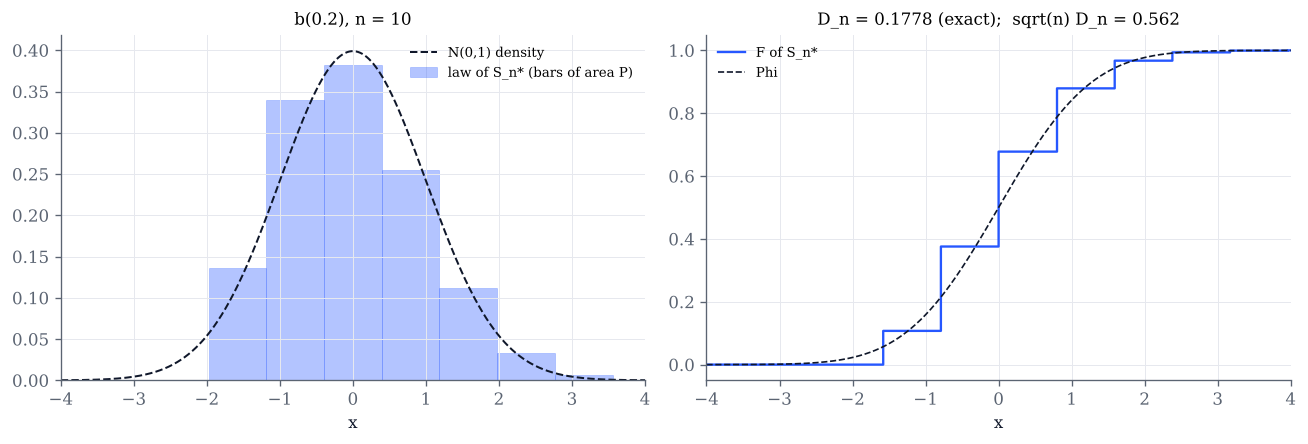

In [3]:
def clt_demo(law="bernoulli", n=10, par=0.2):
    L = law_from(law, par)
    x = np.linspace(-4, 4, 801)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
    a1.plot(x, stats.norm.pdf(x), color=INK, lw=1.2, ls="--", label="N(0,1) density")
    if L.sum_law is None:
        z = simulate_standardised(L, n, 200_000, seed=2026)
        a1.hist(z, bins=np.linspace(-4, 4, 81), density=True, color=COBALT, alpha=0.35, label="simulated S_n*")
        zs = np.sort(z)
        a2.step(zs, np.arange(1, zs.size + 1) / zs.size, where="post", color=COBALT, lw=1.2, label="F of S_n* (empirical)")
        D, how = empirical_kolmogorov(z), "estimated"
    else:
        S = L.sum_law(n)
        s = math.sqrt(n * L.var)
        if L.lattice:
            k = np.arange(int(S.ppf(1e-9)), int(S.ppf(1 - 1e-9)) + 1)
            xs = (k - n * L.mean) / s
            a1.bar(xs, S.pmf(k) * s, width=1 / s, color=COBALT, alpha=0.35, edgecolor=COBALT, lw=0.4,
                   label="law of S_n* (bars of area P)")
        else:
            a1.plot(x, s * S.pdf(n * L.mean + x * s), color=COBALT, lw=1.6, label="density of S_n*")
        a2.plot(x, standardised_cdf(L, n, x), color=COBALT, lw=1.4, drawstyle="steps-post" if L.lattice else "default",
                label="F of S_n*")
        D, how = kolmogorov_distance(L, n), "exact"
    a2.plot(x, stats.norm.cdf(x), color=INK, lw=1.0, ls="--", label="Phi")
    a1.set(xlim=(-4, 4), xlabel="x", title=f"{L.name}, n = {n}")
    a2.set(xlim=(-4, 4), xlabel="x", title=f"D_n = {D:.4f} ({how});  sqrt(n) D_n = {math.sqrt(n) * D:.3f}")
    a1.legend(fontsize=8, loc="upper right")
    a2.legend(fontsize=8, loc="upper left")
    fig.tight_layout()
    plt.show()

clt_demo()

In [4]:
# Explore: for b(0.5) the bars hug the Gaussian already for n = 20; for b(0.02) or Exp(1) the law of S_n* stays
# skewed much longer. Compare sqrt(n) D_n for several n: it settles to a constant (Exercise 17.6).
interact(clt_demo,
         law=Dropdown(options=["bernoulli", "poisson", "exponential", "gamma", "uniform"], value="bernoulli",
                      description="law"),
         n=IntSlider(value=10, min=1, max=500, step=1, continuous_update=False, description="n"),
         par=FloatSlider(value=0.2, min=0.02, max=0.98, step=0.02, continuous_update=False, description="parameter"));

## 2. The proof: characteristic functions

The proof of Theorem 17.1 shows that the characteristic function of $S_n^*$ is $\Phi_{S_n^*}(t)=\Phi_Y\big(\frac t{\sqrt n}\big)^n$, with
$Y=\frac{X-\mu}\sigma$, and that it tends to $e^{-t^2/2}$ for every $t$, by the expansion $\Phi_Y(u)=1-\frac{u^2}2+o(u^2)$. Below: the
real part and the modulus of $\Phi_{S_n^*}(t)$ against $e^{-t^2/2}$. For an integer-valued law, $|\Phi_Y|$ is periodic, so for a fixed $n$
the modulus returns to $1$ at $|t|=2\pi\sigma\sqrt n$: the convergence is pointwise, not uniform on $\mathbb R$.

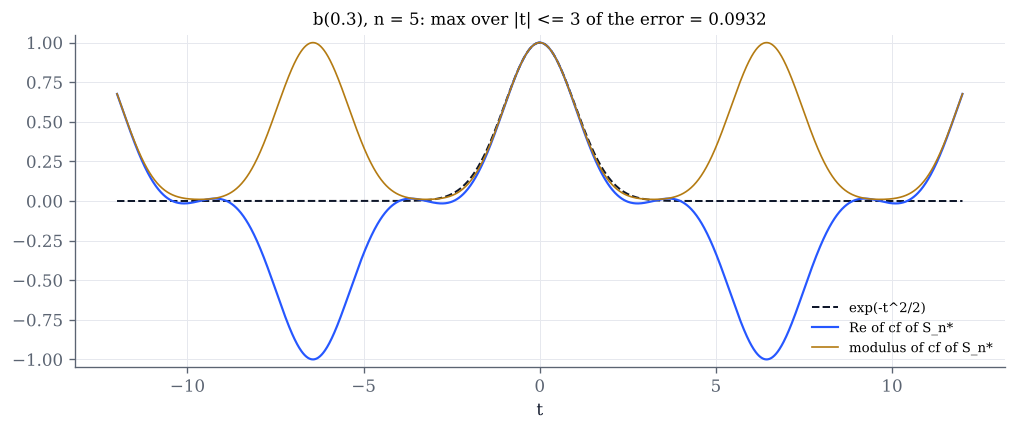

In [5]:
def cf_demo(law="bernoulli", n=5, par=0.3, tmax=12.0):
    L = law_from(law, par)
    t = np.linspace(-tmax, tmax, 2001)
    phi = standardised_cf(L, t, n)
    fig, ax = plt.subplots(figsize=(10, 3.6))
    ax.plot(t, np.exp(-t ** 2 / 2), color=INK, lw=1.2, ls="--", label="exp(-t^2/2)")
    ax.plot(t, phi.real, color=COBALT, lw=1.3, label="Re of cf of S_n*")
    ax.plot(t, np.abs(phi), color=GOLD, lw=1.0, label="modulus of cf of S_n*")
    ax.set(xlabel="t", ylim=(-1.05, 1.05), title=f"{L.name}, n = {n}: max over |t| <= 3 of the error = "
           f"{np.max(np.abs(phi - np.exp(-t ** 2 / 2))[np.abs(t) <= 3]):.4f}")
    ax.legend(fontsize=8, loc="lower right")
    plt.show()

cf_demo()

In [6]:
# Explore: increase n and watch the curves merge on any fixed window of t; widen the window to find the periodic bumps.
interact(cf_demo,
         law=Dropdown(options=["bernoulli", "poisson", "exponential", "gamma", "uniform"], value="bernoulli",
                      description="law"),
         n=IntSlider(value=5, min=1, max=200, continuous_update=False, description="n"),
         par=FloatSlider(value=0.3, min=0.02, max=0.98, step=0.02, continuous_update=False, description="parameter"),
         tmax=FloatSlider(value=12.0, min=3.0, max=60.0, step=1.0, continuous_update=False, description="t max"));

## 3. The normal approximation of the binomial and the continuity correction

For $Y\sim B(n,p)$ and an integer $k$, $\mathbb P(Y>k)=\mathbb P(Y>k+\varepsilon)$ for every $\varepsilon\in[0,1)$, and the central limit
theorem gives $\mathbb P(Y>k)\approx1-\Phi\big(\frac{k+\varepsilon-np}{\sqrt{np(1-p)}}\big)$. The continuity correction is
$\varepsilon=\frac12$ (Remark 17.9). The default is the election poll of Example 17.8, $n=100$, $p=0.4$, $k=50$. The shaded area is the
Gaussian approximation; the gold bars are the exact probability.

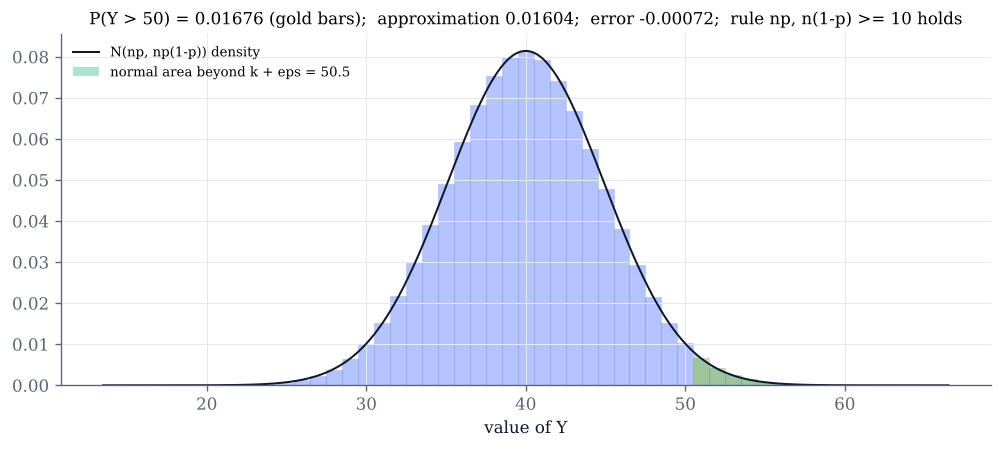

eps = 0, 1/2, 1: [0.02061, 0.01604, 0.01237]  exact: 0.01676


In [7]:
def binomial_demo(n=100, p=0.4, k=50, eps=0.5):
    k = min(k, n)
    sd = math.sqrt(n * p * (1 - p))
    lo, hi = max(0, int(n * p - 5 * sd) - 1), min(n, int(n * p + 5 * sd) + 2)
    j = np.arange(lo, hi + 1)
    pmf = stats.binom.pmf(j, n, p)
    fig, ax = plt.subplots(figsize=(10, 3.8))
    ax.bar(j, pmf, width=1.0, color=np.where(j > k, GOLD, COBALT), alpha=0.35, edgecolor=GREY, lw=0.3)
    x = np.linspace(lo - 0.5, hi + 0.5, 800)
    ax.plot(x, binomial_normal_density(x, n, p), color=INK, lw=1.2, label="N(np, np(1-p)) density")
    xs = x[x >= k + eps]
    ax.fill_between(xs, binomial_normal_density(xs, n, p), color=GREEN, alpha=0.35, lw=0,
                    label=f"normal area beyond k + eps = {k + eps:g}")
    exact, approx = float(binomial_tail(k, n, p)), float(normal_tail(k, n, p, eps))
    ok = "holds" if normal_rule(n, p) else "fails"
    ax.set(xlabel="value of Y", title=f"P(Y > {k}) = {exact:.5f} (gold bars);  approximation {approx:.5f};  "
           f"error {approx - exact:+.5f};  rule np, n(1-p) >= 10 {ok}")
    ax.legend(fontsize=8, loc="upper left")
    plt.show()
    print("eps = 0, 1/2, 1:", [round(float(normal_tail(k, n, p, e)), 5) for e in (0.0, 0.5, 1.0)], " exact:", round(exact, 5))

binomial_demo()

In [8]:
# Explore: for p = 1/2 the correction eps = 1/2 is nearly exact; for small p (skewed binomial) the best eps moves away from 1/2.
interact(binomial_demo,
         n=IntSlider(value=100, min=5, max=1000, step=5, continuous_update=False, description="n"),
         p=FloatSlider(value=0.4, min=0.01, max=0.99, step=0.01, continuous_update=False, description="p"),
         k=IntSlider(value=50, min=0, max=1000, continuous_update=False, description="k"),
         eps=FloatSlider(value=0.5, min=0.0, max=1.0, step=0.05, continuous_update=False, description="eps"));

## 4. The delta method

If $\sqrt n(X_n-\theta)\xrightarrow{\mathcal L}\mathcal N(0,\sigma^2(\theta))$ and $g'(\theta)\ne0$, then
$\sqrt n(g(X_n)-g(\theta))\xrightarrow{\mathcal L}\mathcal N(0,g'(\theta)^2\sigma^2(\theta))$ (Theorem 17.12). If $g'(\theta)=0\neq g''(\theta)$, the
right scale is $n$, and $n(g(X_n)-g(\theta))\xrightarrow{\mathcal L}\sigma^2(\theta)\frac{g''(\theta)}2\chi^2(1)$ (Theorem 17.15). Here $X_n=\bar X_n$
for the chosen law, $\theta$ is its mean, and $2\cdot10^5$ values are simulated. When $g'(\theta)=0$ (for instance $g(x)=x(1-x)$ with
$b(\frac12)$, or $g(x)=\cos(x-\theta)$), the second-order scaling is used automatically.

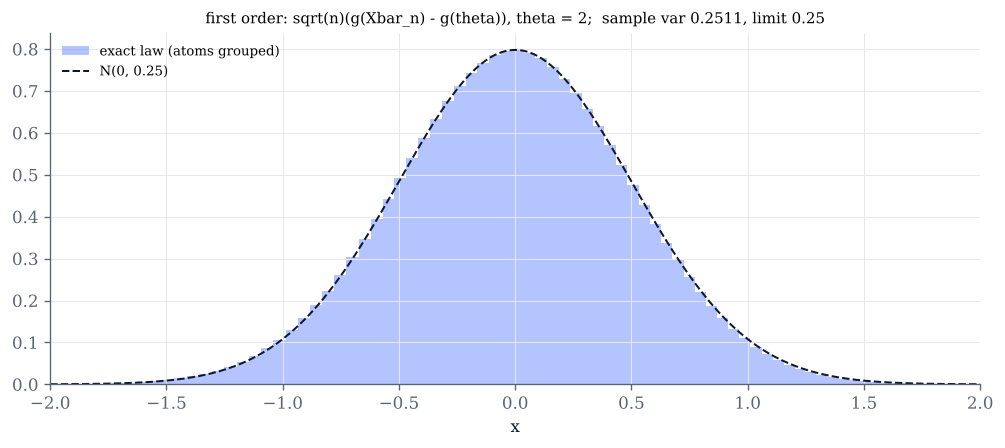

In [9]:
FUNCS = {   # name: (g, g', g'') as functions of x and theta
    "sqrt(x)": (lambda x, th: np.sqrt(np.maximum(x, 0)), lambda th: 0.5 / math.sqrt(th), lambda th: -0.25 * th ** -1.5),
    "log(x)": (lambda x, th: np.log(np.maximum(x, 1e-300)), lambda th: 1 / th, lambda th: -1 / th ** 2),
    "arcsin(sqrt(x))": (lambda x, th: np.arcsin(np.sqrt(np.clip(x, 0, 1))),
                        lambda th: 0.5 / math.sqrt(th * (1 - th)), lambda th: (2 * th - 1) / (4 * (th * (1 - th)) ** 1.5)),
    "x(1-x)": (lambda x, th: x * (1 - x), lambda th: 1 - 2 * th, lambda th: -2.0),
    "x^2": (lambda x, th: x ** 2, lambda th: 2 * th, lambda th: 2.0),
    "cos(x - theta)": (lambda x, th: np.cos(x - th), lambda th: 0.0, lambda th: -1.0),
}

def delta_demo(law="poisson", g="sqrt(x)", n=200, par=2.0):
    L = law_from(law, par)
    th = L.mean
    gf, g1, g2 = FUNCS[g]
    try:
        d1, d2 = g1(th), g2(th)
    except (ValueError, ZeroDivisionError):
        print(f"g = {g} is not differentiable at theta = {th:g}; choose another law or parameter")
        return
    xb = sample_means(L, n, 200_000, seed=2026)
    fig, ax = plt.subplots(figsize=(10, 3.8))
    if abs(d1) > 1e-12:
        w = math.sqrt(n) * (gf(xb, th) - gf(th, th))
        v = float(delta_variance(d1, L.var))
        x = np.linspace(-4 * math.sqrt(v), 4 * math.sqrt(v), 400)
        drawn = False
        if L.lattice:   # exact law, with bins holding whole blocks of atoms (no aliasing)
            S = L.sum_law(n)
            k = np.arange(int(S.ppf(1e-9)), int(S.ppf(1 - 1e-9)) + 1)
            c = max(1, int(round(0.1 * math.sqrt(v) * math.sqrt(n) / abs(d1))))
            centre = int(round(n * th))
            ek = centre - 0.5 + c * np.arange((k[0] - centre) // c - 1, (k[-1] - centre) // c + 3)
            ek = np.unique(np.clip(ek, k[0] - 0.5, k[-1] + 0.5))
            with np.errstate(all="ignore"):
                ex = math.sqrt(n) * (gf(ek / n, th) - gf(th, th))
            dx = np.diff(ex)
            if np.all(np.isfinite(ex)) and (np.all(dx > 0) or np.all(dx < 0)):
                dens = np.histogram(k, bins=ek, weights=S.pmf(k))[0] / np.abs(dx)
                if dx[0] < 0:
                    ex, dens = ex[::-1], dens[::-1]
                ax.stairs(dens, ex, fill=True, color=COBALT, alpha=0.35, label="exact law (atoms grouped)")
                drawn = True
        if not drawn and not L.lattice:
            ax.hist(w, bins=np.linspace(x[0], x[-1], 81), density=True, color=COBALT, alpha=0.35, label="simulated")
            drawn = True
        if drawn:
            ax.plot(x, stats.norm.pdf(x, 0, math.sqrt(v)), color=INK, lw=1.2, ls="--", label=f"N(0, {v:.4g})")
        else:   # a lattice law and a g that is not monotone on the atoms: distribution functions do not alias
            ws = np.sort(w)
            ax.step(ws, np.arange(1, ws.size + 1) / ws.size, where="post", color=COBALT, lw=1.2,
                    label="empirical CDF (simulated)")
            ax.plot(x, stats.norm.cdf(x, 0, math.sqrt(v)), color=INK, lw=1.2, ls="--", label=f"CDF of N(0, {v:.4g})")
        ax.set_xlim(x[0], x[-1])
        title = f"first order: sqrt(n)(g(Xbar_n) - g(theta)), theta = {th:g};  sample var {w.var():.4g}, limit {v:.4g}"
    else:
        w = n * (gf(xb, th) - gf(th, th))
        c = L.var * d2 / 2
        x = np.linspace(min(0, 6 * c), max(0, 6 * c), 400)
        ws = np.sort(w)
        ax.step(ws, np.arange(1, ws.size + 1) / ws.size, where="post", color=COBALT, lw=1.2, label="empirical CDF")
        ax.plot(x, second_order_cdf(x, L.var, d2), color=INK, lw=1.2, ls="--", label=f"CDF of {c:.4g} chi2(1)")
        ax.set_xlim(x[0], x[-1])
        title = f"second order (g'(theta) = 0): n(g(Xbar_n) - g(theta)), theta = {th:g};  mean {w.mean():.4g}, limit {c:.4g}"
    ax.set(xlabel="x", title=title)
    ax.title.set_fontsize(9)
    ax.legend(fontsize=8, loc="upper left")
    plt.show()

delta_demo()

In [10]:
# Explore: sqrt(x) with Poisson, or arcsin(sqrt(x)) with Bernoulli, gives limit variance 1/4 whatever the parameter;
# x(1-x) with b(p) switches to the second-order regime at p = 1/2 (and is poor for p close to 1/2 unless n is huge).
interact(delta_demo,
         law=Dropdown(options=["poisson", "bernoulli", "exponential", "gamma", "uniform"], value="poisson", description="law"),
         g=Dropdown(options=list(FUNCS), value="sqrt(x)", description="g"),
         n=IntSlider(value=200, min=5, max=5000, step=5, continuous_update=False, description="n"),
         par=FloatSlider(value=2.0, min=0.02, max=10.0, step=0.02, continuous_update=False, description="parameter"));

## 5. Variance stabilisation

Example 17.18 looks for $g$ with $g'(\theta)^2\sigma^2(\theta)$ constant: $g=\int\frac{\mathrm d\theta}{\sigma(\theta)}$. For Poisson means, $\sigma^2(\lambda)=\lambda$
and $g(x)=\sqrt x$; for Bernoulli means, $\sigma^2(p)=p(1-p)$ and $g(x)=\arcsin\sqrt x$ (Exercise 17.3). Below, for each value of the
parameter, the **exact** variance of $\sqrt n(\bar X_n-\theta)$ and of $\sqrt n(g(\bar X_n)-g(\theta))$, computed from the binomial or Poisson
law of $n\bar X_n$. The first follows $\sigma^2(\theta)$; the second is flat at $\frac14$, except where $n\sigma^2(\theta)$ is small.

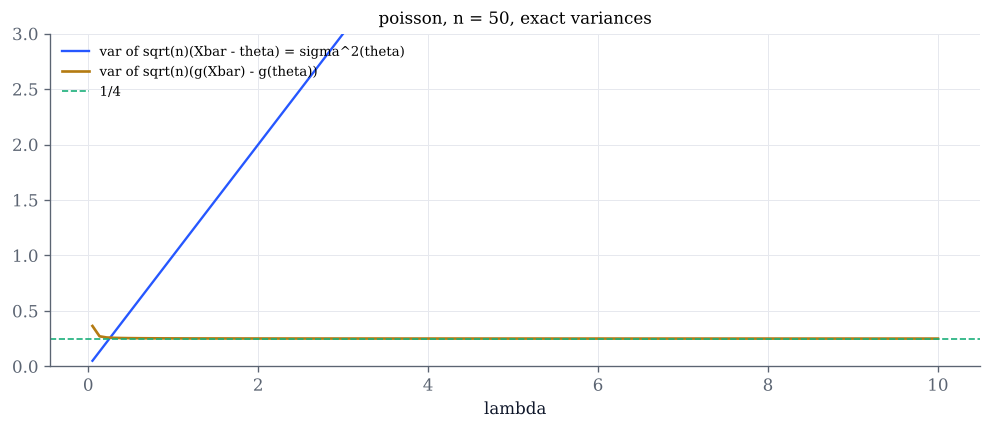

In [11]:
def stabilise_demo(family="poisson", n=50):
    fig, ax = plt.subplots(figsize=(10, 3.6))
    if family == "poisson":
        th = np.linspace(0.05, 10, 120)
        g = lambda x: np.sqrt(x)
        def law(t):
            S = stats.poisson(n * t)
            k = np.arange(0, int(S.ppf(1 - 1e-12)) + 2)
            return k, S.pmf(k)
    else:
        th = np.linspace(0.01, 0.99, 99)
        g = lambda x: np.arcsin(np.sqrt(x))
        def law(t):
            k = np.arange(n + 1)
            return k, stats.binom.pmf(k, n, t)
    raw, stab = [], []
    for t in th:
        k, w = law(t)
        for out, v in ((raw, math.sqrt(n) * (k / n - t)), (stab, math.sqrt(n) * (g(k / n) - g(t)))):
            out.append(np.sum(w * v ** 2) - np.sum(w * v) ** 2)
    ax.plot(th, raw, color=COBALT, lw=1.4, label="var of sqrt(n)(Xbar - theta) = sigma^2(theta)")
    ax.plot(th, stab, color=GOLD, lw=1.6, label="var of sqrt(n)(g(Xbar) - g(theta))")
    ax.axhline(0.25, color=GREEN, ls="--", lw=1.0, label="1/4")
    ax.set(xlabel="lambda" if family == "poisson" else "p", ylim=(0, min(1.2 * max(raw), 3.0)),
           title=f"{family}, n = {n}, exact variances")
    ax.legend(fontsize=8, loc="upper left" if family == "poisson" else "upper right")
    plt.show()

stabilise_demo()

In [12]:
# Explore: where does the stabilised variance leave 1/4? Near lambda = 0 (Poisson) and near p = 0, 1 (Bernoulli),
# that is, where n sigma^2(theta) is small. Increase n to push the bad region to the edge.
interact(stabilise_demo,
         family=Dropdown(options=["poisson", "bernoulli"], value="poisson", description="family"),
         n=IntSlider(value=50, min=5, max=1000, step=5, continuous_update=False, description="n"));

## 6. Convergence in law without convergence of the variances; the exam problem

Example 17.20: $Z_n=\sqrt nY_n+X_n$, with $Y_n\sim b(\frac1n)$ independent of the standardised binomial $X_n$, tends to $\mathcal N(0,1)$ in law,
but $\operatorname{var}(Z_n)=2-\frac1n\to2$: a rare spike of height $\sqrt n$ carries a whole unit of variance. Left: the empirical distribution
function of $2\cdot10^5$ values of $Z_n$ against $\Phi$, with the sample variance. Right: the exam problem of Example 17.22, $X_n=YZ_n$ with
$\mathbb P(Z_n=\alpha_n)=\mathbb P(Z_n=0)=\frac12$: its characteristic function $\frac12(e^{-\alpha^2t^2/2}+1)$, exact and estimated from
samples, tends to $1$ as $\alpha\to0$.

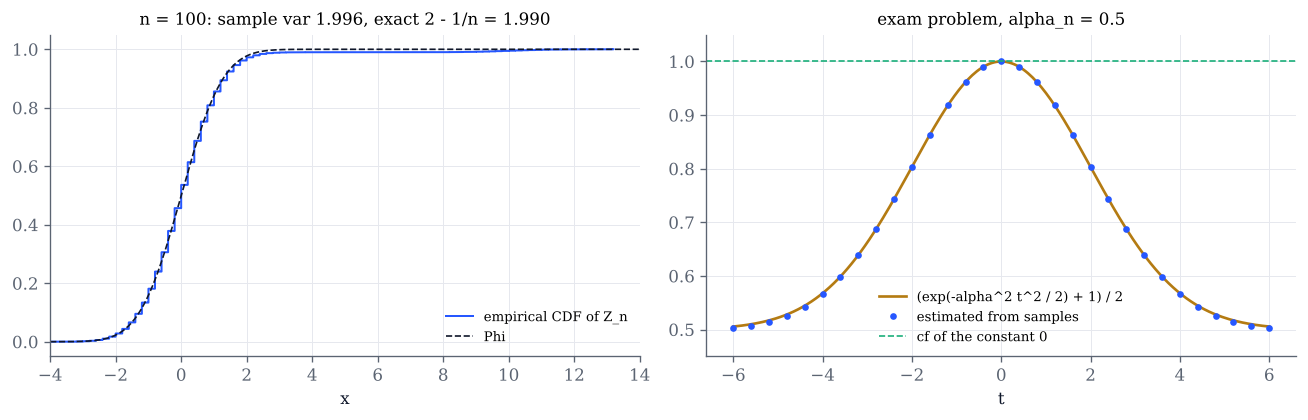

In [13]:
def last_demo(n=100, alpha=0.5):
    z = np.sort(variance_counterexample_sample(n, 200_000, seed=2026))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
    x = np.linspace(-4, 4 + math.sqrt(n), 600)
    a1.step(z, np.arange(1, z.size + 1) / z.size, where="post", color=COBALT, lw=1.2, label="empirical CDF of Z_n")
    a1.plot(x, stats.norm.cdf(x), color=INK, ls="--", lw=1.0, label="Phi")
    a1.set(xlim=(-4, 4 + math.sqrt(n)), xlabel="x",
           title=f"n = {n}: sample var {z.var():.3f}, exact 2 - 1/n = {2 - 1 / n:.3f}")
    a1.legend(fontsize=8, loc="lower right")
    t = np.linspace(-6, 6, 241)
    xs = exam_sample(alpha, 100_000, seed=2026)
    a2.plot(t, exam_cf(t, alpha), color=GOLD, lw=1.6, label="(exp(-alpha^2 t^2 / 2) + 1) / 2")
    a2.plot(t[::8], [np.mean(np.cos(tt * xs)) for tt in t[::8]], "o", color=COBALT, ms=3, label="estimated from samples")
    a2.axhline(1.0, color=GREEN, ls="--", lw=1.0, label="cf of the constant 0")
    a2.set(ylim=(0.45, 1.05), xlabel="t", title=f"exam problem, alpha_n = {alpha:g}")
    a2.legend(fontsize=8, loc="lower center")
    fig.tight_layout()
    plt.show()

last_demo()

In [14]:
# Explore: the variance of Z_n stays near 2 for every n, while its CDF approaches Phi; as alpha -> 0 the
# characteristic function of the exam problem flattens to 1.
interact(last_demo,
         n=IntSlider(value=100, min=4, max=2000, step=4, continuous_update=False, description="n"),
         alpha=FloatSlider(value=0.5, min=0.0, max=3.0, step=0.05, continuous_update=False, description="alpha_n"));

## Things to try

- In section 1, take $b(0.02)$: from which $n$ does the rule $np\ge10$ hold, and what is $D_n$ there? Compare with $b(0.5)$ at the same $n$.
- In section 1, for $\mathrm{Exp}(1)$ read off $\sqrt nD_n$ for $n=10,100,500$: does it approach $\frac{2}{6\sqrt{2\pi}}\approx0.133$?
- In section 3, set $n=20$, $p=0.5$, $k=11$ (the shaded example of Figure 17.2) and try $\varepsilon=0$, $\frac12$, $1$.
- In section 3, with $n=100$, $p=0.4$, $k=50$, find the $\varepsilon$ that makes the approximation exact (about $0.414$).
- In section 4, choose $b(p)$ with $g(x)=x(1-x)$ and move $p$ towards $\frac12$: when does the first-order picture break down?
- In section 6, why does the empirical CDF of $Z_n$ have a small step far to the right? How tall is it?